# Human vs. LLM Text Detection
M.S. Data Science capstone, Montclair State University. Binary classification of human-written vs. LLM-generated text.

## 1. Data loading and balanced sampling
Dataset: [Human vs. LLM Text Corpus](https://www.kaggle.com/datasets/starblasters8/human-vs-llm-text-corpus) (Kaggle, MIT license). Requires a Kaggle API key (`kaggle.json`); never commit it.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

# -------------------------------
# 1. Create Kaggle directory
# -------------------------------
os.makedirs("/root/.kaggle", exist_ok=True)

# Copy API key only if not already present
if not os.path.exists("/root/.kaggle/kaggle.json"):
    shutil.copy("/content/kaggle (1).json", "/root/.kaggle/kaggle.json")
    os.chmod("/root/.kaggle/kaggle.json", 0o600)
    print("✅ Kaggle API key installed.")
else:
    print("🔑 Kaggle API key already exists. Skipping copy.")


# -------------------------------
# 2. Download dataset only if needed
# -------------------------------
zip_path = "/content/human-vs-llm-text-corpus.zip"

if not os.path.exists("data.csv"):  # main file in dataset
    print("⬇️ Downloading dataset...")
    !kaggle datasets download -d starblasters8/human-vs-llm-text-corpus -p /content
    print("📦 Unzipping...")
    !unzip -o "/content/human-vs-llm-text-corpus.zip" -d /content
else:
    print("✅ Dataset already exists. Skipping download.")


# -------------------------------
# 3. Show resulting files
# -------------------------------
print("📁 Files in content:", os.listdir("/content"))

✅ Kaggle API key installed.
⬇️ Downloading dataset...
Dataset URL: https://www.kaggle.com/datasets/starblasters8/human-vs-llm-text-corpus
License(s): MIT
100% 1.92G/1.92G [00:19<00:00, 218MB/s]
100% 1.92G/1.92G [00:19<00:00, 104MB/s]
📦 Unzipping...
Archive:  /content/human-vs-llm-text-corpus.zip
  inflating: /content/data.csv       
  inflating: /content/data.parquet   
  inflating: /content/distribution.csv  
  inflating: /content/distribution.parquet  
  inflating: /content/prompts.csv    
  inflating: /content/prompts.parquet  
📁 Files in content: ['.config', 'human-vs-llm-text-corpus.zip', 'prompts.parquet', 'prompts.csv', 'distribution.csv', 'kaggle (1).json', 'data.csv', 'distribution.parquet', 'data.parquet', 'drive', 'sample_data']


In [ ]:
import pandas as pd
df = pd.read_csv('/content/data.csv')
df.head()

,text,source,prompt_id,text_length,word_count
0,"Federal law supersedes state law, and cannabis...",Bloom-7B,0,967,157
1,Miles feels restless after working all day. He...,Bloom-7B,0,5068,778
2,So first of I am danish. That means that I fol...,Bloom-7B,0,1602,267
3,In this paper we present a novel rule-based ap...,Bloom-7B,0,5469,848
4,"Most social progressives, love democracy, and ...",Bloom-7B,0,2379,380


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 788922 entries, 0 to 788921
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   text         788922 non-null  object
 1   source       788922 non-null  object
 2   prompt_id    788922 non-null  int64 
 3   text_length  788922 non-null  int64 
 4   word_count   788922 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 30.1+ MB


In [ ]:
print("Dataset Columns:", df.columns)

Dataset Columns: Index(['text', 'source', 'prompt_id', 'text_length', 'word_count'], dtype='object')


In [ ]:
df['source'].value_counts()

,count
source,
Human,347692
GPT-3.5,52346
Text-Davinci-003,22860
Text-Davinci-002,21436
OPT-1.3B,18467
...,...
Toppy-M-7B,433
LLaMA-2-7B,409
Dolphin-Mixtral-8x7B,407


In [ ]:
df.rename(columns={'source': 'label'}, inplace=True)

In [ ]:
df.rename(columns={'source': 'label'}, inplace=True)

# Balance the sample: 5,000 human + 5,000 LLM examples
df_human = df[df['label'].str.lower() == 'human'].sample(n=5000, random_state=42)
df_llm = df[df['label'].str.lower() != 'human'].sample(n=5000, random_state=42)

# Combine and shuffle
subset_df = pd.concat([df_human, df_llm]).sample(frac=1, random_state=42).reset_index(drop=True)

# Optional: Save subset for reuse
subset_df.to_csv('/content/drive/MyDrive/llm_human_subset.csv', index=False)

# Check balance
subset_df['label'].value_counts()

,count
label,
Human,5000
GPT-3.5,607
Text-Davinci-002,277
Text-Davinci-003,247
OPT-30B,210
...,...
OpenHermes-2-Mistral-7B,6
Dolphin-Mixtral-8x7B,5
Gemini-Pro,5


In [ ]:
subset_df.head()

,text,label,prompt_id,text_length,word_count
0,That's a funny way of putting it. I feel like ...,GPT-3.5,0,472,81
1,Driverless cars would have never crossed our m...,Human,5,3639,625
2,Keras Tuner is a hyperparameter tuner for Kera...,Human,0,264,38
3,I hurried across the parking lot and stopped w...,Human,0,6974,1216
4,Certified Nurse Practitioners and Their Roles ...,Human,0,8412,1257


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/llm_human_subset.csv')
df.rename(columns={'source': 'label'}, inplace=True)  # in case not already renamed

# Create binary label: 1 for human, 0 for LLM
df['binary_label'] = df['label'].apply(lambda x: 1 if x.lower() == 'human' else 0)

## 2. Stylometric feature engineering (spaCy)
Average word length, lexical diversity, average sentence length, and text length.

In [ ]:
!pip install spacy
!python -m spacy download en_core_web_sm

In [ ]:
import spacy
nlp = spacy.load("en_core_web_sm")
nlp.disable_pipes("ner", "tagger", "parser")  # still fast
nlp.add_pipe("sentencizer")  # enables doc.sents without parser

In [ ]:
def extract_features(text):
    doc = nlp(text)
    words = [token.text for token in doc if token.is_alpha]
    word_count = len(words)
    sentence_count = len(list(doc.sents))
    unique_words = len(set(words))
    char_count = sum(len(word) for word in words)

    return pd.Series({
        'avg_word_length': char_count / word_count if word_count else 0,
        'lexical_diversity': unique_words / word_count if word_count else 0,
        'avg_sentence_length': word_count / sentence_count if sentence_count else 0
    })

# Add original columns for modeling
feature_df['text_length'] = df['text_length'] if 'text_length' in df.columns else df['text'].apply(len)
feature_df['word_count'] = df['word_count'] if 'word_count' in df.columns else df['text'].apply(lambda x: len(x.split()))
feature_df['label'] = df['binary_label']

from tqdm import tqdm
tqdm.pandas()
feature_df = df['text'].progress_apply(extract_features)

/usr/local/lib/python3.12/dist-packages/spacy/pipeline/lemmatizer.py:188: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
  0%|          | 0/10000 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/spacy/pipeline/lemmatizer.py:188: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
100%|██████████| 10000/10000 [05:24<00:00, 30.86it/s]


In [ ]:
# This adds the correct label column for modeling
feature_df['label'] = df['binary_label']

## 3. Classical machine learning
Random Forest, Logistic Regression, Naive Bayes, Linear SVM, XGBoost, and MLP on stylometric features.

In [ ]:
from sklearn.model_selection import train_test_split

X = feature_df.drop(columns=['label'])  # only feature columns
y = feature_df['label']                 # target labels

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Train model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Classification Report:
               precision    recall  f1-score   support

           0       0.68      0.68      0.68       987
           1       0.69      0.69      0.69      1013

    accuracy                           0.69      2000
   macro avg       0.69      0.69      0.69      2000
weighted avg       0.69      0.69      0.69      2000

Confusion Matrix:
 [[672 315]
 [314 699]]


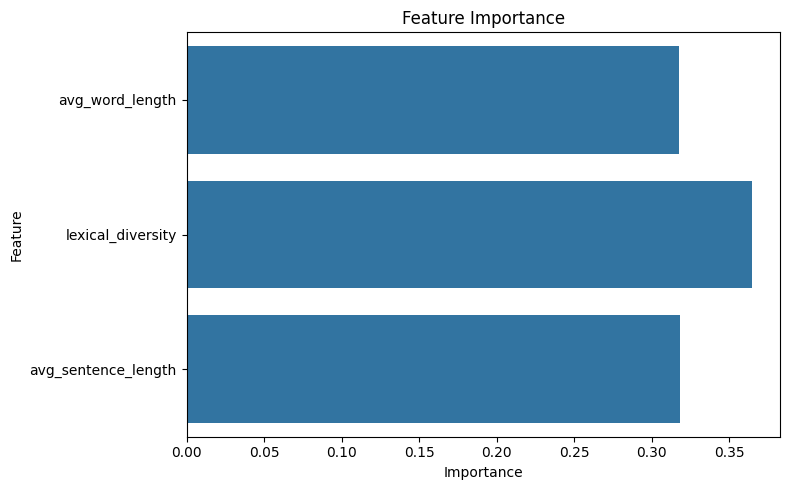

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot importance
importance = model.feature_importances_
features = X.columns

plt.figure(figsize=(8, 5))
sns.barplot(x=importance, y=features)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 3b. Model vs. simulated human annotator
Note: human judgments are **simulated** (80% accurate labels), and the Random Forest here is scored on data that includes its training set, so these numbers are exploratory only.

In [ ]:
import numpy as np
# Instead of sampling 100 rows
sample_df = df.copy()  # Use all 1000 rows from your subset
sample_df['true_label'] = sample_df['binary_label']

# Simulate human annotations (80% accurate)
np.random.seed(42)
sample_df['human_judgment'] = sample_df['true_label'].apply(
    lambda x: x if np.random.rand() < 0.8 else 1 - x
)

# Step 1: Simulate features using your function
sample_features = sample_df['text'].apply(extract_features)

# Step 2: Add the original columns before prediction (IN the same DataFrame)
sample_features['text_length'] = sample_df['text'].apply(len)
sample_features['word_count'] = sample_df['text'].apply(lambda x: len(x.split()))

# Reorder to match training feature order
sample_features = sample_features[X.columns]  # X from earlier train-test split

# Step 3: Predict using trained model
sample_df['model_prediction'] = model.predict(sample_features)
# Evaluation
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix

print("Accuracy - Human vs. True:", accuracy_score(sample_df['true_label'], sample_df['human_judgment']))
print("Accuracy - Model vs. True:", accuracy_score(sample_df['true_label'], sample_df['model_prediction']))
print("Agreement - Human vs. Model (Cohen's Kappa):", cohen_kappa_score(sample_df['human_judgment'], sample_df['model_prediction']))
print("Confusion Matrix - Human vs. Model:")
print(confusion_matrix(sample_df['human_judgment'], sample_df['model_prediction']))

/usr/local/lib/python3.12/dist-packages/spacy/pipeline/lemmatizer.py:188: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)


Accuracy - Human vs. True: 0.8038
Accuracy - Model vs. True: 0.9369
Agreement - Human vs. Model (Cohen's Kappa): 0.5333998133599254
Confusion Matrix - Human vs. Model:
[[3828 1162]
 [1171 3839]]


In [ ]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)
print("Logistic Regression:\n", classification_report(y_test, y_pred_log))

Logistic Regression:
               precision    recall  f1-score   support

           0       0.63      0.60      0.61       987
           1       0.63      0.66      0.64      1013

    accuracy                           0.63      2000
   macro avg       0.63      0.63      0.63      2000
weighted avg       0.63      0.63      0.63      2000



In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)
print("Naive Bayes:\n", classification_report(y_test, y_pred_nb))

Naive Bayes:
               precision    recall  f1-score   support

           0       0.57      0.49      0.52       987
           1       0.56      0.64      0.60      1013

    accuracy                           0.56      2000
   macro avg       0.56      0.56      0.56      2000
weighted avg       0.56      0.56      0.56      2000



In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)
print("SVM:\n", classification_report(y_test, y_pred_svm))

SVM:
               precision    recall  f1-score   support

           0       0.63      0.59      0.61       987
           1       0.62      0.67      0.64      1013

    accuracy                           0.63      2000
   macro avg       0.63      0.63      0.63      2000
weighted avg       0.63      0.63      0.63      2000



In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
print("XGBoost:\n", classification_report(y_test, y_pred_xgb))

XGBoost:
               precision    recall  f1-score   support

           0       0.68      0.65      0.67       987
           1       0.68      0.70      0.69      1013

    accuracy                           0.68      2000
   macro avg       0.68      0.68      0.68      2000
weighted avg       0.68      0.68      0.68      2000



/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [16:00:38] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=42)
mlp_model.fit(X_train, y_train)

y_pred_mlp = mlp_model.predict(X_test)
print("MLP Neural Network:\n", classification_report(y_test, y_pred_mlp))

MLP Neural Network:
               precision    recall  f1-score   support

           0       0.72      0.63      0.67       987
           1       0.68      0.77      0.72      1013

    accuracy                           0.70      2000
   macro avg       0.70      0.70      0.70      2000
weighted avg       0.70      0.70      0.70      2000



In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

def stratified_sample(df, n, label_col='label', random_state=42):
    # If n >= dataset size, return full df
    if n >= len(df):
        return df.copy()
    # compute proportion per class
    classes = df[label_col].unique()
    parts = []
    for c in classes:
        cls = df[df[label_col] == c]
        k = int(np.round(n * len(cls) / len(df)))
        parts.append(cls.sample(k, random_state=random_state))
    sample = (pd.concat(parts)
              .sample(frac=1, random_state=random_state)
              .reset_index(drop=True))
    return sample

sizes = [1000, 5000]
samples = {}
for s in sizes:
    samples[s] = stratified_sample(df, s)
    print(f"{s}: {len(samples[s])} rows, class balance:\n", samples[s]['label'].value_counts(normalize=True))

1000: 1002 rows, class balance:
 label
Human                        0.499002
GPT-3.5                      0.060878
Text-Davinci-002             0.027944
Text-Davinci-003             0.024950
OPT-30B                      0.020958
OPT-1.3B                     0.019960
Nous-Hermes-LLaMA-2-13B      0.015968
Mistral-7B                   0.011976
T0-11B                       0.011976
OpenChat-3.5                 0.010978
Flan-T5-Base                 0.010978
Flan-T5-XXL                  0.010978
LLaMA-65B                    0.010978
LLaMA-13B                    0.010978
GLM-130B                     0.010978
GPT-4                        0.009980
LLaMA-30B                    0.009980
LLaMA-7B                     0.009980
OPT-2.7B                     0.009980
Flan-T5-Large                0.009980
Flan-T5-XL                   0.009980
OPT-6.7B                     0.009980
PaLM-2                       0.009980
Bloom-7B                     0.009980
Flan-T5-Small                0.009980
OPT-350M   

## 4. Deep learning: LSTM and 1D-CNN
Learning curves across training sample sizes.


🧠 Training on sample size: 1000
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/20
Epoch 3/20
Epoch 4/20
Epoch 5/20
Epoch 6/20
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch 7/20
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.
✅ Sample size 1000 → Validation Accuracy: 0.7300

🧠 Training on sample size: 5000
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/20
Epoch 3/20
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch 4/20
Epoch 5/20
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 6/20
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.
✅ Sample size 5000 → Validation Accuracy: 0.7710

🧠 Training on sample size: 10000
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/20
Epoch 3/20
Epoch 4/20
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch 5/20
Epoch 6/20
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch 7/20
Epoch 8/20
Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 5.
✅ Sample size 10000 → Validation Accuracy: 0.7955


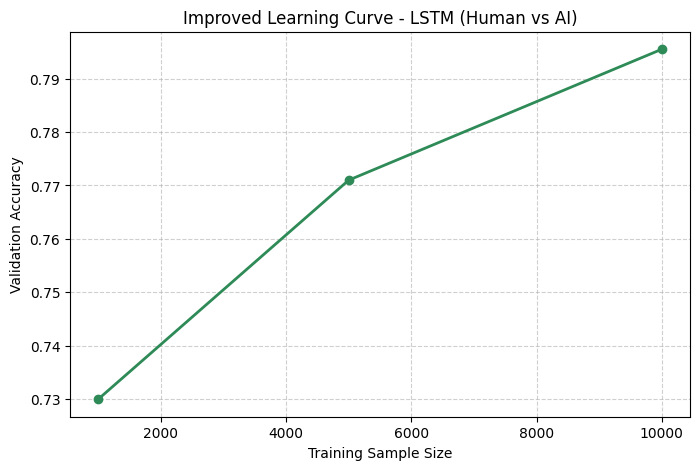

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Data Prep ---
max_len = 150
vocab_size = 10000
embedding_dim = 100

# Fit tokenizer ONCE
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(df['text'].astype(str).tolist())

def stratified_sample(df, n, label_col='binary_label', random_state=42):
    if n >= len(df): return df.copy()
    proportions = df[label_col].value_counts(normalize=True)
    sample_sizes = (proportions * n).round().astype(int)
    parts = [
        df[df[label_col] == cls].sample(
            min(k, len(df[df[label_col] == cls])), random_state=random_state
        )
        for cls, k in sample_sizes.items()
    ]
    return pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)

def build_better_lstm(vocab_size, emb_dim, max_len):
    model = Sequential([
        Embedding(vocab_size, emb_dim, input_length=max_len),
        LSTM(128, dropout=0.3, recurrent_dropout=0.3, return_sequences=True),
        LSTM(64, dropout=0.3, recurrent_dropout=0.3),
        Dense(64, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ])
    model.compile(loss='binary_crossentropy',
                  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  metrics=['accuracy'])
    return model

results = []
for s in [1000, 5000, 10000]:
    print(f"\n🧠 Training on sample size: {s}")
    samp = stratified_sample(df, s, label_col='binary_label')

    texts = samp['text'].astype(str).tolist()
    labels = samp['binary_label'].astype(int).values

    seq = tokenizer.texts_to_sequences(texts)
    X = pad_sequences(seq, maxlen=max_len, padding='post')
    X_train, X_val, y_train, y_val = train_test_split(X, labels, test_size=0.2,
                                                      random_state=42, stratify=labels)

    model = build_better_lstm(vocab_size, embedding_dim, max_len)

    es = EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True, verbose=1)
    lr_sched = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        callbacks=[es, lr_sched],
        verbose=1
    )

    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print(f"✅ Sample size {s} → Validation Accuracy: {val_acc:.4f}")
    results.append((s, val_acc))

# --- Plot learning curve ---
sizes = [r[0] for r in results]
accs = [r[1] for r in results]

plt.figure(figsize=(8,5))
plt.plot(sizes, accs, marker='o', linewidth=2, color='seagreen')
plt.title("Improved Learning Curve - LSTM (Human vs AI)")
plt.xlabel("Training Sample Size")
plt.ylabel("Validation Accuracy")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


⚙️ Training CNN on sample size: 1000
Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/8
Epoch 3/8
Epoch 4/8
Epoch 5/8
Epoch 6/8
Epoch 7/8
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 5.
✅ Sample size 1000 → Validation Accuracy: 0.7150

⚙️ Training CNN on sample size: 5000
Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/8
Epoch 3/8
Epoch 4/8
Epoch 5/8
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 3.
✅ Sample size 5000 → Validation Accuracy: 0.7660

⚙️ Training CNN on sample size: 10000
Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/8
Epoch 3/8
Epoch 4/8
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
✅ Sample size 10000 → Validation Accuracy: 0.7710

⚙️ Training CNN on sample size: 20000
Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/8
Epoch 3/8
Epoch 4/8
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
✅ Sample size 20000 → Validation Accuracy: 0.7810

⚙️ Training CNN on sample size: 50000
Epoch 1/8


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 2/8
Epoch 3/8
Epoch 4/8
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
✅ Sample size 50000 → Validation Accuracy: 0.7800


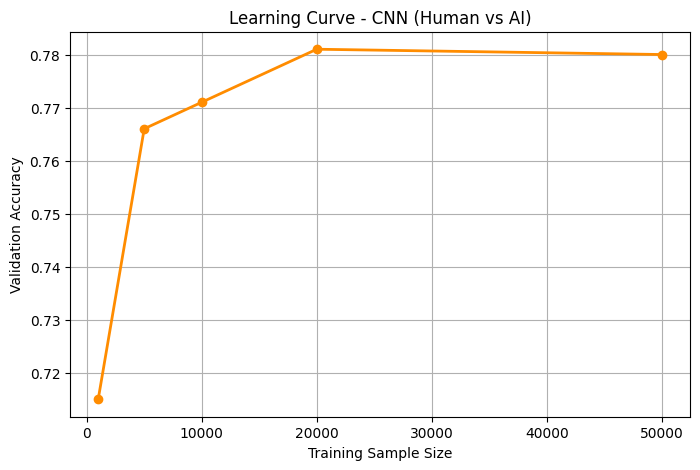

In [ ]:
# ---------------------------------------------------------
# CNN Learning Curve Experiment for Human vs AI Detection
# ---------------------------------------------------------
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Stratified sampling function (same as before) ---
def stratified_sample(df, n, label_col='binary_label', random_state=42):
    if n >= len(df):
        return df.copy()
    proportions = df[label_col].value_counts(normalize=True)
    sample_sizes = (proportions * n).round().astype(int)
    parts = [
        df[df[label_col] == cls].sample(
            min(k, len(df[df[label_col] == cls])), random_state=random_state
        )
        for cls, k in sample_sizes.items()
    ]
    sample = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return sample

# --- Define small CNN model ---
def build_small_cnn(vocab_size=5000, emb_dim=64, max_len=150):
    model = Sequential([
        Embedding(vocab_size, emb_dim, input_length=max_len),
        Conv1D(filters=128, kernel_size=5, activation='relu', padding='same'),
        GlobalMaxPooling1D(),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# --- Train and evaluate on increasing dataset sizes ---
max_len = 150
vocab_size = 5000
results = []

for s in [1000, 5000, 10000, 20000, 50000]:
    print(f"\n⚙️ Training CNN on sample size: {s}")
    samp = stratified_sample(df, s, label_col='binary_label')

    texts = samp['text'].astype(str).tolist()
    labels = samp['binary_label'].astype(int).values

    # Tokenize and pad
    tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
    tokenizer.fit_on_texts(texts)
    seq = tokenizer.texts_to_sequences(texts)
    X = pad_sequences(seq, maxlen=max_len, padding='post')

    # Split train/validation
    X_train, X_val, y_train, y_val = train_test_split(
        X, labels, test_size=0.2, random_state=42, stratify=labels
    )

    # Build model
    model = build_small_cnn(vocab_size=vocab_size, emb_dim=64, max_len=max_len)
    es = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)

    # Train model
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=32,
        callbacks=[es],
        verbose=1
    )

    # Evaluate model
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    print(f"✅ Sample size {s} → Validation Accuracy: {val_acc:.4f}")
    results.append((s, val_acc))

# --- Plot learning curve ---
sizes = [r[0] for r in results]
accs = [r[1] for r in results]

plt.figure(figsize=(8,5))
plt.plot(sizes, accs, marker='o', linewidth=2, color='darkorange')
plt.title("Learning Curve - CNN (Human vs AI)")
plt.xlabel("Training Sample Size")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.show()

## 5. Error analysis
Inspecting disagreements by readability, sentiment, pronoun use, grammar, and heuristic failure reasons.

In [ ]:
# Step 1: Filter disagreements
disagreements = sample_df[sample_df['human_judgment'] != sample_df['model_prediction']]

# Step 2: Sample a few to inspect
example_rows = disagreements.sample(n=5, random_state=42)

# Step 3: Display key info
for idx, row in example_rows.iterrows():
    print(f"\n🔹 Example {idx}")
    print(f"True Label: {'Human' if row['true_label'] == 1 else 'LLM'}")
    print(f"Human Annotator Guess: {'Human' if row['human_judgment'] == 1 else 'LLM'}")
    print(f"Model Prediction: {'Human' if row['model_prediction'] == 1 else 'LLM'}")
    print("Text Preview:")
    print(row['text'][:500] + '...')  # print first 500 characters only


🔹 Example 2324
True Label: LLM
Human Annotator Guess: Human
Model Prediction: LLM
Text Preview:
While crisis simulations could be an effective way to train individuals to respond to emergencies or high-pressure situations, debates serve a different purpose. Debates allow individuals to present and defend their opinions on a variety of subjects, from political issues to philosophical ideas. Debates also foster critical thinking skills and the ability to see multiple perspectives, which are essential in any profession or field. While debates may not simulate a crisis situation, they do provi...

🔹 Example 5637
True Label: Human
Human Annotator Guess: LLM
Model Prediction: Human
Text Preview:
Post-Trial Process in Criminal Law Report (Assessment)

Table of Contents
 1. How It Works
 2. Fixing the Error
 3. New Evidence
 4. Defendant’s Rights
 5. The Repercussions
 6. References

A defendant can file a motion for a new hearing after the trial is over. The court may review the case to over

In [ ]:
!pip install textstat

In [ ]:
import textstat
from textblob import TextBlob
import re

def analyze_text_features(text):
    # Readability score
    readability = textstat.flesch_reading_ease(text)

    # Sentiment polarity
    sentiment = TextBlob(text).sentiment.polarity

    # Lexical diversity (using simple .split() to avoid NLTK)
    words = text.split()
    lexical_diversity = len(set(words)) / len(words) if words else 0

    # Pronoun count
    pronouns = re.findall(r'\b(I|we|you|he|she|they|me|us|him|her|them)\b', text, flags=re.IGNORECASE)
    pronoun_count = len(pronouns)

    return {
        'readability': readability,
        'sentiment': sentiment,
        'lexical_diversity': lexical_diversity,
        'pronoun_count': pronoun_count
    }

In [ ]:
# Clean and ensure text is string
disagreements['text'] = disagreements['text'].astype(str)

# Analyze features
disagreement_features = disagreements['text'].apply(analyze_text_features)

# Combine
disagreement_analysis = pd.concat([disagreements.reset_index(drop=True), disagreement_features.apply(pd.Series)], axis=1)

# Display sample with error-proof preview
for idx, row in disagreement_analysis.sample(n=5, random_state=42).iterrows():
    text_preview = str(row['text'])[:500] + '...' if pd.notnull(row['text']) else "[Missing Text]"

    print(f"\n🔍 Example {idx}")
    print(f"True Label: {'Human' if row['true_label'] == 1 else 'LLM'}")
    print(f"Human Annotator Guess: {'Human' if row['human_judgment'] == 1 else 'LLM'}")
    print(f"Model Prediction: {'Human' if row['model_prediction'] == 1 else 'LLM'}")
    print("Text Preview:")
    print(text_preview)
    print(f"\n🧠 Readability Score: {row['readability']}")
    print(f"💬 Sentiment Polarity: {row['sentiment']:.2f}")
    print(f"🧍 Pronouns Used: {row['pronoun_count']}")
    print(f"🧠 Lexical Diversity: {row['lexical_diversity']:.2f}")

/tmp/ipython-input-3124594094.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  disagreements['text'] = disagreements['text'].astype(str)



🔍 Example 2451
True Label: LLM
Human Annotator Guess: LLM
Model Prediction: LLM
Text Preview:
[Missing Text]

🧠 Readability Score: 65.79821428571432
💬 Sentiment Polarity: 0.25
🧍 Pronouns Used: 5.0
🧠 Lexical Diversity: 0.80

🔍 Example 7709
True Label: LLM
Human Annotator Guess: LLM
Model Prediction: LLM
Text Preview:
[Missing Text]

🧠 Readability Score: 32.7441761967919
💬 Sentiment Polarity: 0.11
🧍 Pronouns Used: 6.0
🧠 Lexical Diversity: 0.42

🔍 Example 3914
True Label: LLM
Human Annotator Guess: LLM
Model Prediction: LLM
Text Preview:
[Missing Text]

🧠 Readability Score: 57.2808204757313
💬 Sentiment Polarity: -0.06
🧍 Pronouns Used: 53.0
🧠 Lexical Diversity: 0.45

🔍 Example 2256
True Label: Human
Human Annotator Guess: LLM
Model Prediction: Human
Text Preview:
Canadian vs. American Post-Abortion Care Research Paper

The United States of America is one of the world’s leading countries in terms of the development of science, research, technology, and medicine. The citizens and residents 

In [ ]:
# Drop rows where any feature is NaN
feature_cols = ['readability', 'sentiment', 'pronoun_count', 'lexical_diversity']
disagreement_clean = disagreement_analysis.dropna(subset=feature_cols).copy()

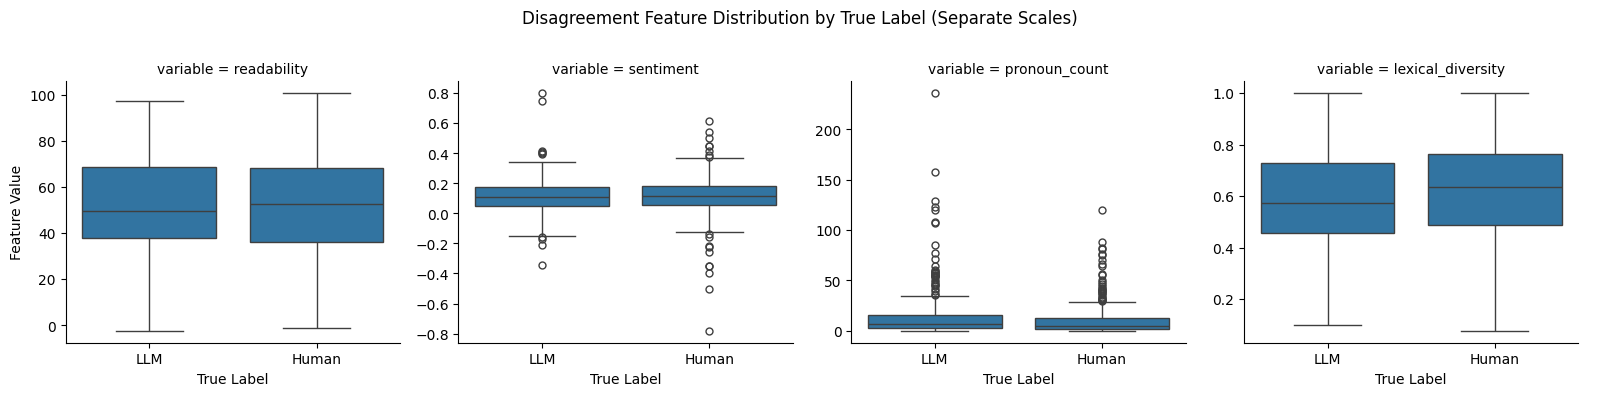

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Melted dataframe already prepared
melted = disagreement_clean.melt(id_vars='true_label', value_vars=feature_cols)
melted['true_label'] = melted['true_label'].map({0: 'LLM', 1: 'Human'})

# Plot with separate scales
g = sns.catplot(
    data=melted, x='true_label', y='value', col='variable',
    kind='box', sharey=False, height=4, aspect=1
)

g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Disagreement Feature Distribution by True Label (Separate Scales)")
g.set_axis_labels("True Label", "Feature Value")
plt.show()

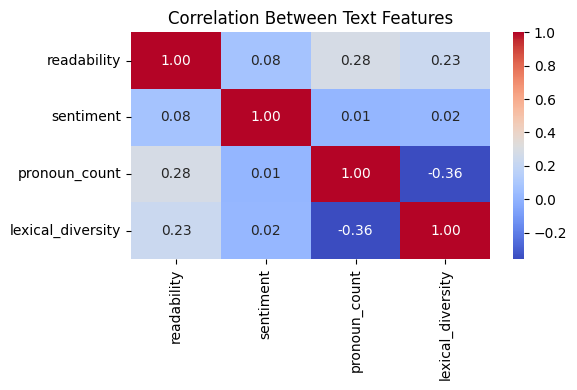

In [ ]:
# Compute correlation
corr = disagreement_clean[feature_cols].corr()

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Between Text Features")
plt.tight_layout()
plt.show()

In [ ]:
nlp.enable_pipe("senter")

In [ ]:
def has_nonstandard_grammar(text):
    doc = nlp(text)
    frag_count = sum(
        1 for sent in doc.sents
        if not any(tok.dep_ == 'nsubj' for tok in sent) or not any(tok.pos_ == 'VERB' for tok in sent)
    )
    return frag_count > 0

In [ ]:
contradiction_patterns = [
    r"\bbut\b.*?\bhowever\b",
    r"\byet\b.*?\balso\b",
    r"\bon the other hand\b",
    r"\bdespite\b.*?\bstill\b"
]

In [ ]:
!pip install transformers --quiet
from transformers import pipeline

In [ ]:
sentiment_pipeline = pipeline("sentiment-analysis")

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


In [ ]:
df['sentiment'] = df['text'].apply(lambda x: sentiment_pipeline(x[:512])[0]['label'])

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

# Load spaCy
nlp = spacy.load("en_core_web_sm")

# Define heuristics
def has_nonstandard_grammar(text):
    doc = nlp(text)
    frag_count = sum(1 for sent in doc.sents if len(sent) < 5 or not any(tok.dep_ == 'nsubj' for tok in sent))
    return frag_count >= 1

def has_ironic_or_cultural_cue(text):
    cues = ["as if", "yeah right", "because of course", "totally", "sarcasm", "obviously", "great job", "classic"]
    return any(cue in text.lower() for cue in cues)

def has_logical_inconsistency(text):
    contradiction_patterns = [r"\bbut\b.*\bhowever\b", r"\byet\b.*\balso\b", r"\bon the other hand\b"]
    return any(re.search(pattern, text.lower()) for pattern in contradiction_patterns)

# Apply to DataFrame `df` (replace if your disagreement set is named differently)
df['nonstandard_grammar'] = df['text'].apply(has_nonstandard_grammar)
df['irony_or_culture'] = df['text'].apply(has_ironic_or_cultural_cue)
df['logical_inconsistency'] = df['text'].apply(has_logical_inconsistency)

# Tag dominant reason
def tag_reason(row):
    reasons = []
    if row['irony_or_culture']:
        reasons.append("Humor/Irony/Culture")
    if row['nonstandard_grammar']:
        reasons.append("Nonstandard Grammar")
    if row['logical_inconsistency']:
        reasons.append("Logical Inconsistency")
    return ", ".join(reasons) if reasons else "Unclear"

df['failure_reason'] = df.apply(tag_reason, axis=1)

/tmp/ipython-input-1510581867.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="reason", y="count", palette="viridis")


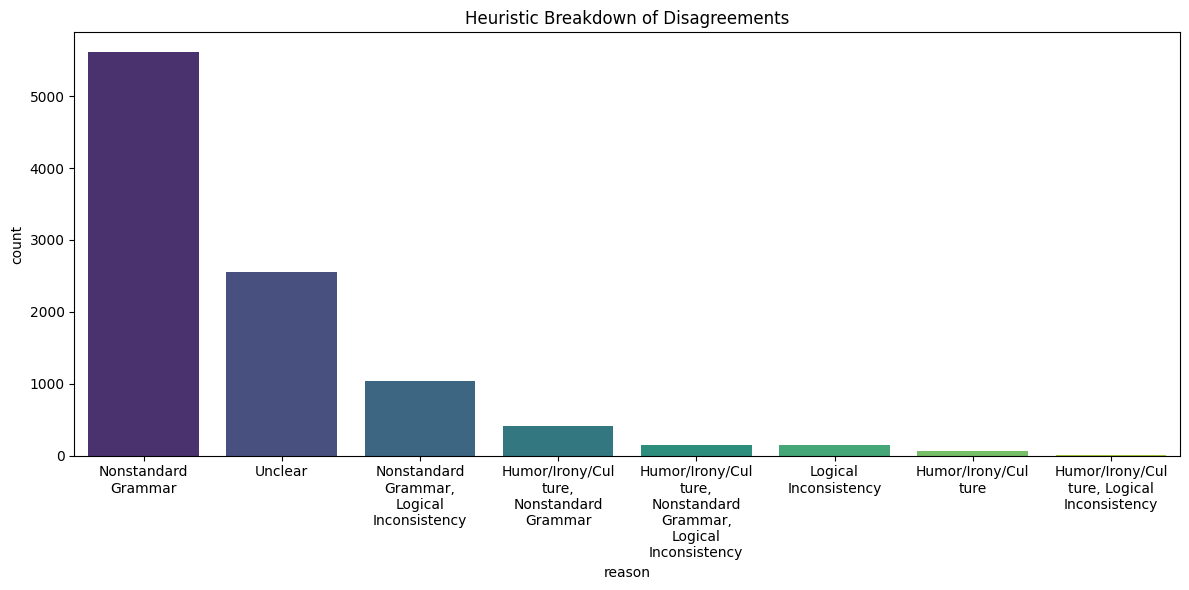

In [ ]:
import textwrap

df_plot = df['failure_reason'].value_counts().reset_index()
df_plot.columns = ["reason", "count"]

df_plot["reason"] = df_plot["reason"].apply(lambda x: "\n".join(textwrap.wrap(x, width=15)))

plt.figure(figsize=(12,6))
sns.barplot(data=df_plot, x="reason", y="count", palette="viridis")
plt.xticks(rotation=0)
plt.title("Heuristic Breakdown of Disagreements")
plt.tight_layout()
plt.show()

## 6. Fine-tuning DistilBERT
Transformer fine-tuning in PyTorch with mixed-precision GPU training.

In [ ]:
!pip -q install -U transformers accelerate scikit-learn matplotlib

import os, gc, math, random, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from tqdm.auto import tqdm

torch.backends.cuda.matmul.allow_tf32 = True
os.environ["TOKENIZERS_PARALLELISM"] = "false"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ CUDA available:", torch.cuda.is_available(), "| Device:", device)

# ---------- Load your data ----------
if 'df' not in globals():
    df = pd.read_csv('/content/drive/MyDrive/llm_human_subset.csv')

if 'binary_label' not in df.columns:
    df['binary_label'] = df['label'].astype(str).str.lower().eq('human').astype(int)

df = df[['text', 'binary_label']].dropna().reset_index(drop=True)
print("📘 Data:", df.shape, "| Human ratio:", df.binary_label.mean())

# ---------- Helpers ----------
def stratified_sample(df, n, label_col='binary_label', seed=42):
    if n >= len(df): return df.copy()
    p = df[label_col].value_counts(normalize=True)
    targets = (p * n).round().astype(int)
    parts = []
    for cls, k in targets.items():
        sub = df[df[label_col]==cls]
        k = min(k, len(sub))
        parts.append(sub.sample(k, random_state=seed))
    out = pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    return out

class TextClsDS(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=192):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True, max_length=self.max_len,
            padding=False, return_tensors=None
        )
        enc['labels'] = self.labels[idx]
        return enc

@torch.no_grad()
def evaluate(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []
    for batch in dataloader:
        batch = {k: torch.tensor(v).to(device) if not isinstance(v, torch.Tensor) else v.to(device) for k,v in batch.items()}
        labels = batch.pop('labels')
        out = model(**batch)
        preds = out.logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='binary', zero_division=0)
    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

def free():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def train_distilbert(sample_size=5000, epochs=4, lr=1e-5, max_len=256):
    model_name = "distilbert-base-uncased"
    print(f"\n🚀 Training {model_name} | n={sample_size:,}")

    dfx = stratified_sample(df, sample_size)
    tr, va = train_test_split(dfx, test_size=0.1, stratify=dfx['binary_label'], random_state=42)

    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    collator = DataCollatorWithPadding(tokenizer)

    train_ds = TextClsDS(tr.text, tr.binary_label.astype(int), tokenizer, max_len)
    val_ds   = TextClsDS(va.text, va.binary_label.astype(int), tokenizer, max_len)

    train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, collate_fn=collator, num_workers=2)
    val_dl   = DataLoader(val_ds, batch_size=16, shuffle=False, collate_fn=collator, num_workers=2)

    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)
    optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)

    total_steps = len(train_dl) * epochs
    sched = get_linear_schedule_with_warmup(optim, num_warmup_steps=int(0.1*total_steps), num_training_steps=total_steps)
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

    best_f1, best_state = -1, None

    for epoch in range(epochs):
        model.train()
        pbar = tqdm(train_dl, desc=f"Epoch {epoch+1}/{epochs}")
        for batch in pbar:
            labels = batch.pop('labels')
            batch = {k: torch.tensor(v).to(device) if not isinstance(v, torch.Tensor) else v.to(device) for k,v in batch.items()}
            labels = labels.to(device)
            with torch.cuda.amp.autocast(enabled=True):
                out = model(**batch, labels=labels)
                loss = out.loss
            scaler.scale(loss).backward()
            scaler.step(optim)
            scaler.update()
            sched.step()
            optim.zero_grad()
            pbar.set_postfix({'loss': f"{loss.item():.4f}"})

        metrics = evaluate(model, val_dl)
        print(f"📊 Epoch {epoch+1}: F1={metrics['f1']:.4f} | Acc={metrics['accuracy']:.4f}")
        if metrics['f1'] > best_f1:
            best_f1, best_state = metrics['f1'], {k: v.cpu() for k,v in model.state_dict().items()}
        free()

    if best_state is not None: model.load_state_dict(best_state)
    save_dir = f"/content/drive/MyDrive/models_distilbert_{sample_size}"
    os.makedirs(save_dir, exist_ok=True)
    model.save_pretrained(save_dir); tokenizer.save_pretrained(save_dir)
    print(f"✅ Saved best model to: {save_dir}")
    return best_f1

sizes = [5000]
results = []
for n in sizes:
    results.append((n, train_distilbert(sample_size=n, epochs=2, max_len=192)))

✅ CUDA available: True | Device: cuda
📘 Data: (10000, 2) | Human ratio: 0.5

🚀 Training distilbert-base-uncased | n=5,000


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

... (4 outputs left out)

📊 Epoch 1: F1=0.7963 | Acc=0.8240


Epoch 2/2:   0%|          | 0/563 [00:00<?, ?it/s]

/tmp/ipython-input-2155099643.py:106: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


📊 Epoch 2: F1=0.7963 | Acc=0.8260
✅ Saved best model to: /content/drive/MyDrive/models_distilbert_5000


In [ ]:
!pip install -q scikit-learn==1.3.2 shap==0.43.0 --force-reinstall

## 7. Explaining DistilBERT predictions
Attention maps, gradient × input saliency, and occlusion tests.

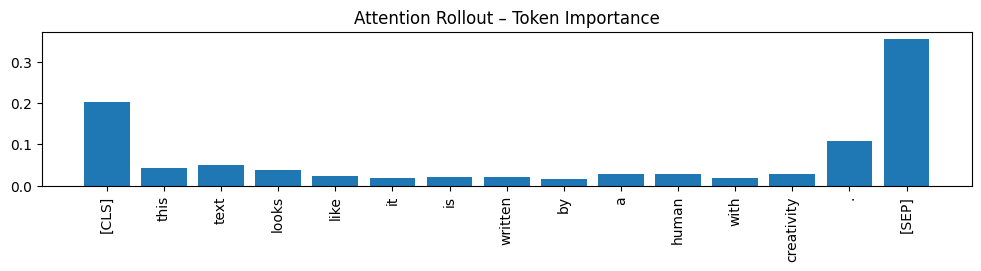

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load saved model
model_path = "/content/drive/MyDrive/models_distilbert_5000"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path, output_attentions=True)
model.to(device)
model.eval()

def get_attention_scores(text):
    encoding = tokenizer(text, return_tensors="pt", truncation=True, max_length=192)
    encoding = {k: v.to(device) for k, v in encoding.items()}

    with torch.no_grad():
        outputs = model(**encoding)
        attentions = outputs.attentions  # list of layers

    # Average over all heads and layers
    # attentions[layer]: (batch, heads, seq, seq)
    attn = torch.stack(attentions).mean(dim=0).mean(dim=1)[0]
    # Get attention from CLS token to all tokens
    scores = attn[0].cpu().numpy()
    return scores, encoding

def visualize_attention(text):
    scores, encoding = get_attention_scores(text)
    tokens = tokenizer.convert_ids_to_tokens(encoding['input_ids'][0])

    plt.figure(figsize=(12, 2))
    plt.bar(range(len(tokens)), scores)
    plt.xticks(range(len(tokens)), tokens, rotation=90)
    plt.title("Attention Rollout – Token Importance")
    plt.show()

# Test
sample_text = "This text looks like it is written by a human with creativity."
visualize_attention(sample_text)

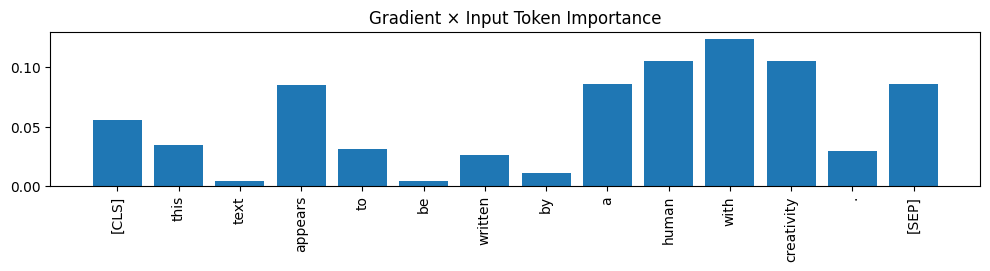

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_path = "/content/drive/MyDrive/models_distilbert_5000"
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)
model.to(device)
model.eval()

def gradient_saliency(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=192)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    input_ids = inputs["input_ids"]

    # Enable gradient tracking
    input_embeds = model.get_input_embeddings()(input_ids)
    input_embeds.retain_grad()

    outputs = model(inputs_embeds=input_embeds)
    target_class = outputs.logits.argmax(dim=-1)

    loss = outputs.logits[0, target_class]
    loss.backward()

    # Grad * Input
    saliency = (input_embeds.grad * input_embeds).sum(dim=-1).squeeze().abs().cpu().detach().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])

    return tokens, saliency

def plot_saliency(tokens, saliency):
    plt.figure(figsize=(12, 2))
    plt.bar(range(len(tokens)), saliency)
    plt.xticks(range(len(tokens)), tokens, rotation=90)
    plt.title("Gradient × Input Token Importance")
    plt.show()

# Example
text = "This text appears to be written by a human with creativity."
tokens, saliency = gradient_saliency(text)
plot_saliency(tokens, saliency)

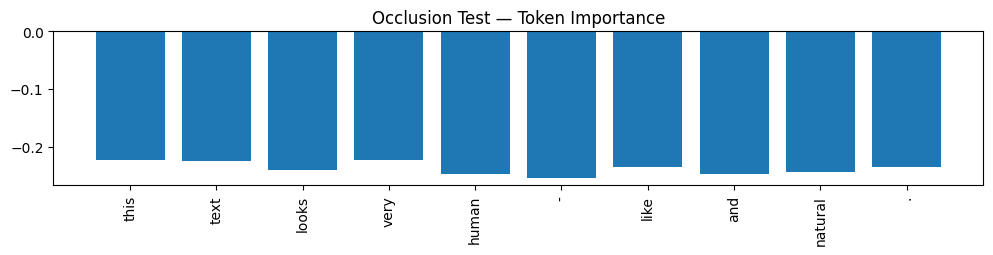

In [ ]:
def occlusion_importance(text):
    full_prob = torch.nn.functional.softmax(
        model(**tokenizer(text, return_tensors='pt').to(device)).logits,
        dim=-1
    )[0].detach().cpu().numpy()

    tokens = tokenizer.tokenize(text)
    importances = []

    for i in range(len(tokens)):
        masked_tokens = tokens[:i] + ["[MASK]"] + tokens[i+1:]
        masked_text = tokenizer.convert_tokens_to_string(masked_tokens)

        prob = torch.nn.functional.softmax(
            model(**tokenizer(masked_text, return_tensors='pt').to(device)).logits,
            dim=-1
        )[0].detach().cpu().numpy()

        drop = full_prob[1] - prob[1]  # drop in "human" prob
        importances.append(drop)

    plt.figure(figsize=(12,2))
    plt.bar(range(len(tokens)), importances)
    plt.xticks(range(len(tokens)), tokens, rotation=90)
    plt.title("Occlusion Test — Token Importance")
    plt.show()

# Test
occlusion_importance("This text looks very human-like and natural.")

## 8. Model comparison
Validation accuracy measured in this notebook.

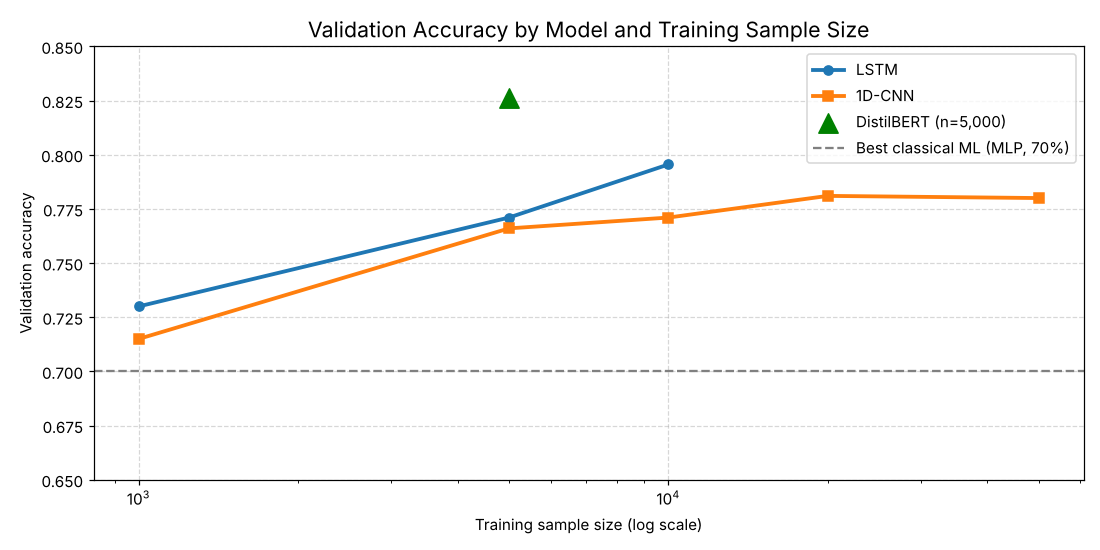

In [ ]:
import matplotlib.pyplot as plt

# Validation accuracy measured in this notebook
lstm_sizes, lstm_acc = [1000, 5000, 10000], [0.730, 0.771, 0.7955]
cnn_sizes,  cnn_acc  = [1000, 5000, 10000, 20000, 50000], [0.715, 0.766, 0.771, 0.781, 0.780]
bert_sizes, bert_acc = [5000], [0.826]   # DistilBERT fine-tuned on the 5,000-text sample

plt.figure(figsize=(10, 5))
plt.plot(lstm_sizes, lstm_acc, marker='o', linewidth=2.5, label="LSTM")
plt.plot(cnn_sizes, cnn_acc, marker='s', linewidth=2.5, label="1D-CNN")
plt.scatter(bert_sizes, bert_acc, marker='^', s=160, color='green', zorder=5, label="DistilBERT (n=5,000)")
plt.axhline(0.70, color='gray', linestyle='--', linewidth=1.5, label="Best classical ML (MLP, 70%)")
plt.xscale('log')
plt.title("Validation Accuracy by Model and Training Sample Size", fontsize=14)
plt.xlabel("Training sample size (log scale)")
plt.ylabel("Validation accuracy")
plt.ylim(0.65, 0.85)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
